In [347]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore') #This ignores all the warnings that might pop up in the code because of deprecated functions or other reasons.

# read the data
File type	Pandas method
.csv=>pd.read_csv(),
.xlsx / .xls=>pd.read_excel(),
.json=>pd.read_json(),
.txt=>pd.read_csv() with a separator,
.sql / database=>pd.read_sql(),
.parquet=>pd.read_parquet()

In [348]:
df= pd.read_csv('insurance.csv')

In [349]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA 

In [350]:
df.shape

(1338, 7)

In [351]:
df.head() #first 5 rows of the dataset

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [352]:
df.info()#gives the info about the colums 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [353]:
df.describe() #gives the statistical info about the dataset :- mean,median , mode , standard deviation etc.

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [354]:
df.isnull().sum() #gives the count of null values in each column

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [355]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [356]:
numeric_columns = ['age', 'bmi', 'children', 'charges']
categorical_columns = ['sex', 'smoker', 'region']

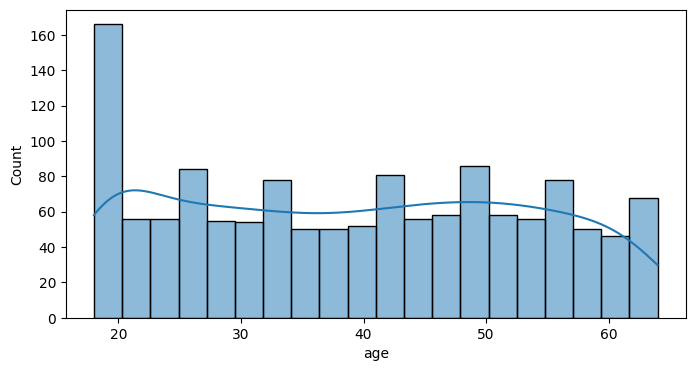

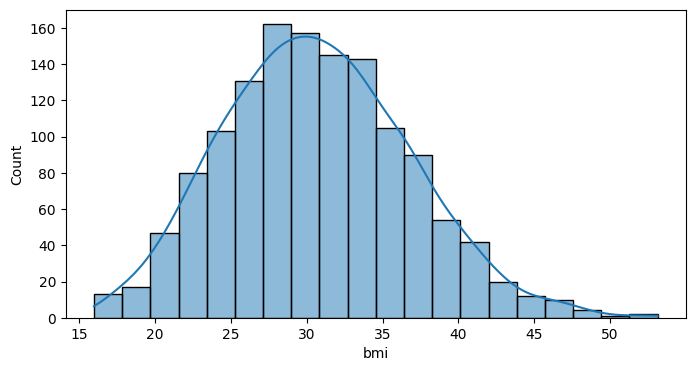

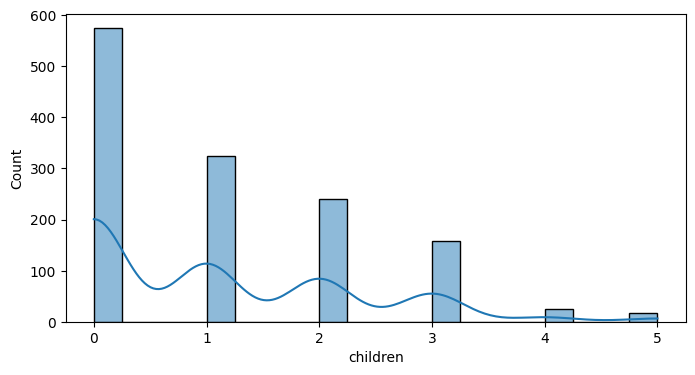

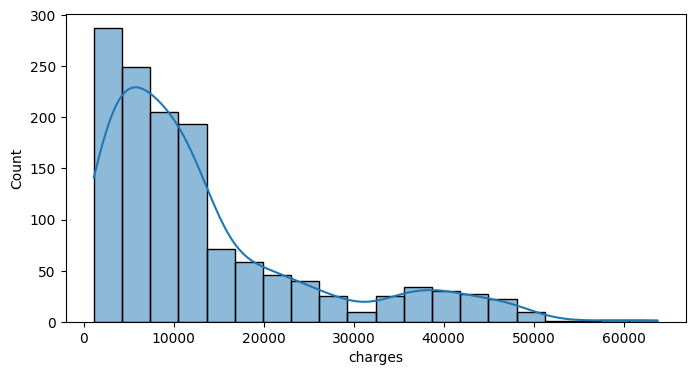

In [357]:
for col in numeric_columns:
    plt.figure(figsize=(8, 4))# this sets the size of the figure to be 8 inches wide and 4 inches tall.
    sns.histplot(df[col], kde=True, bins=20)#this creates a histogram and kde gives kernel density estimate 
                                            #which is a smoothed version of the histogram.

<Axes: xlabel='children', ylabel='count'>

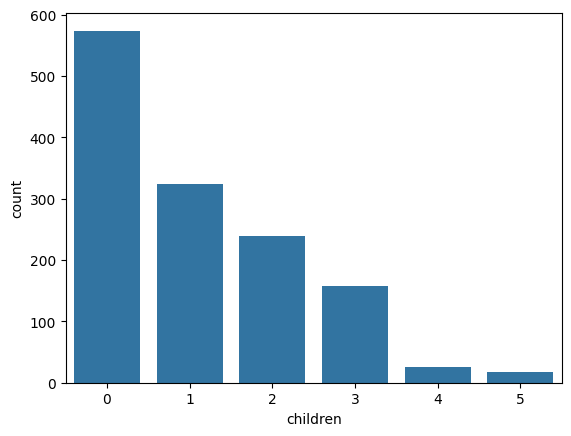

In [358]:
sns.countplot(x=df['children'])  # creates a count plot for the 'children' column

<Axes: xlabel='sex', ylabel='count'>

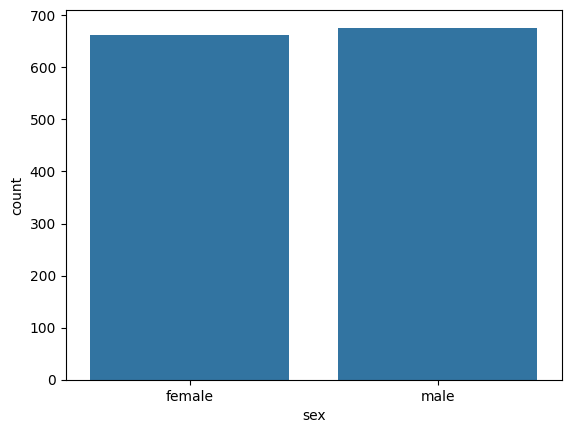

In [359]:
sns.countplot(x=df['sex'])  # creates a count plot for the 'sex' column

<Axes: xlabel='smoker', ylabel='count'>

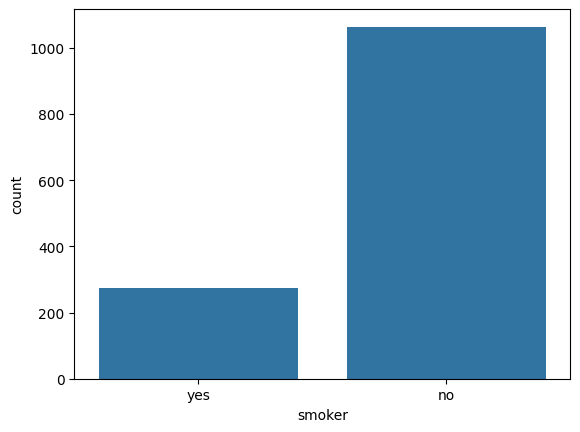

In [360]:
sns.countplot(x=df['smoker'])  # creates a count plot for the 'smoker' column

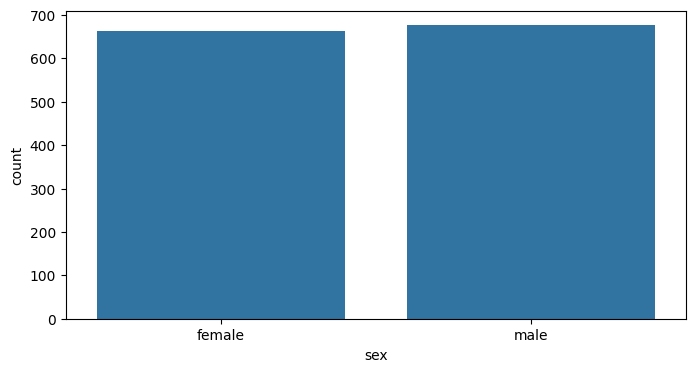

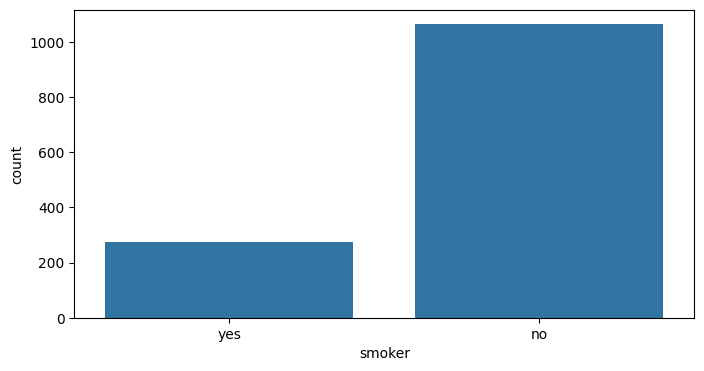

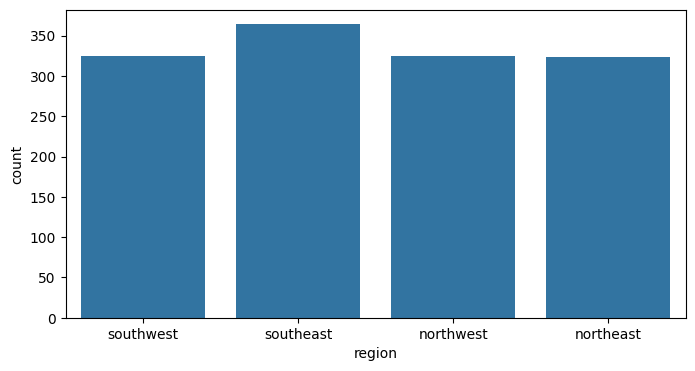

In [361]:
for cols in categorical_columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=df[cols])

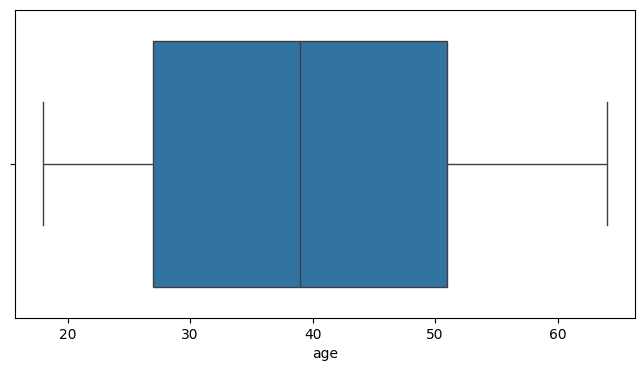

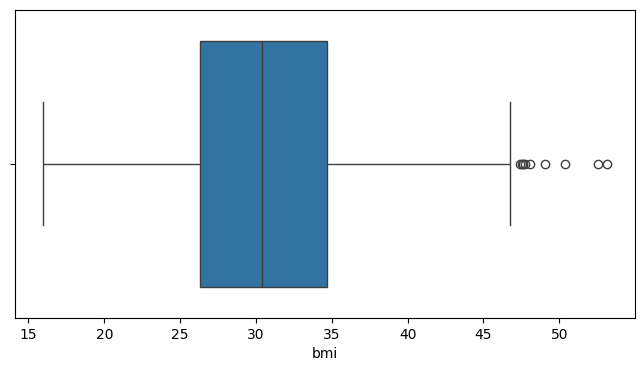

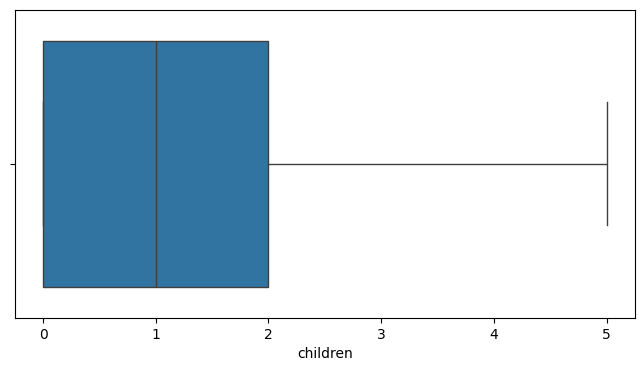

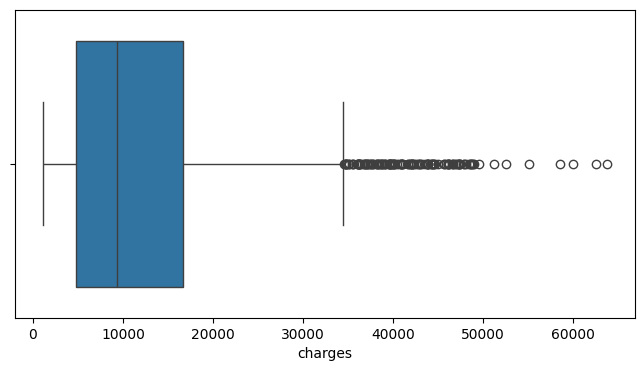

In [362]:
for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col]) #creates a box plot for the specified column in the DataFrame df.
   

<Axes: >

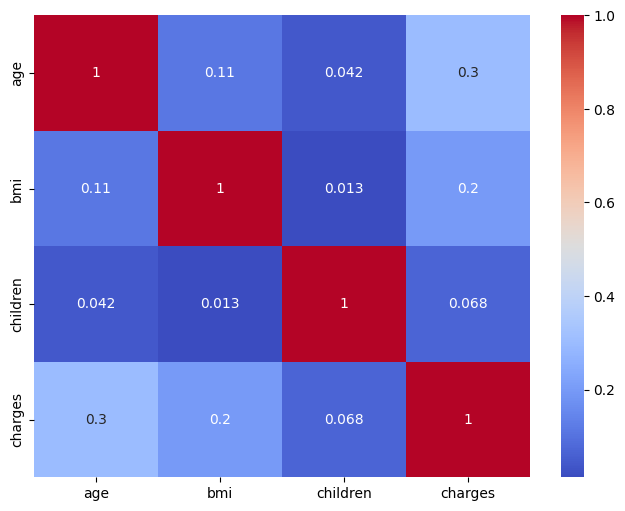

In [363]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
) 
#numeric_only=True ensures that only numeric columns are considered for correlation calculation,
#corr() computes the pairwise correlation of columns,correlation values range from -1 to 1, where 1 indicates a perfect positive correlation, -1 indicates a perfect negative correlation, and 0 indicates no correlation.
#annot=True means that the correlation values will be displayed on the heatmap, and cmap='coolwarm' specifies the color scheme for the heatmap.

# Data Cleaning and Preprocessing 

In [364]:
df_clean=df.copy()

In [365]:
print(df_clean)

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


In [366]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [367]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [368]:
df_clean.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [369]:
df_clean.drop_duplicates(inplace=True) #removes duplicate rows from the DataFrame df_clean. The inplace=True argument means that the operation is performed directly on df_clean, modifying it in place rather than creating a new DataFrame.

In [370]:
df_clean.shape

(1337, 7)

In [371]:
df_clean.isnull().sum() #gives the count of null values in each column

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [372]:
df_clean.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

#### we need to convert the objects into the numbers

In [373]:
df_clean.value_counts('sex') #gives the count of unique values in the 'sex'|| df_clean['sex'].value_counts() can also be used to achieve the same result.

sex
male      675
female    662
Name: count, dtype: int64

## Encoding Begins 

#### converting objects to the numeric values 

In [374]:
df_clean['sex']=df_clean['sex'].map({'male':0,'female':1}) #this maps the values in the 'sex' column

In [375]:
type(df_clean)

pandas.core.frame.DataFrame

In [376]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [377]:
df_clean['smoker']=df_clean['smoker'].map({'yes':1,'no':0})# this maps the values in the 'smoker' column

In [378]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   int64  
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   int64  
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(4), object(1)
memory usage: 83.6+ KB


In [379]:
df_clean.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
region       object
charges     float64
dtype: object

In [380]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


### Renaming the colums

In [381]:
df_clean.rename(columns={'sex':'is_female'}, inplace=True)

In [382]:
df_clean.rename(columns={'smoker':'is_smoker'}, inplace=True)

In [383]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [384]:
df_clean.value_counts('region') #gives the count

region
southeast    364
southwest    325
northeast    324
northwest    324
Name: count, dtype: int64

## One hot Encoding 

In [385]:
df_clean.value_counts('region')

region
southeast    364
southwest    325
northeast    324
northwest    324
Name: count, dtype: int64

In [386]:
df_clean = pd.get_dummies(
    df_clean,
    columns=['region'],
   # drop_first=True
)#this creates dummy variables for the 'region' column in the DataFrame df_clean. 
#The drop_first=True narakham es le notheast lai faaldeko thiyo 

In [387]:
df_clean.columns


Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'],
      dtype='object')

In [388]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False


In [389]:
df_clean= df_clean.astype(int)

In [390]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


# Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

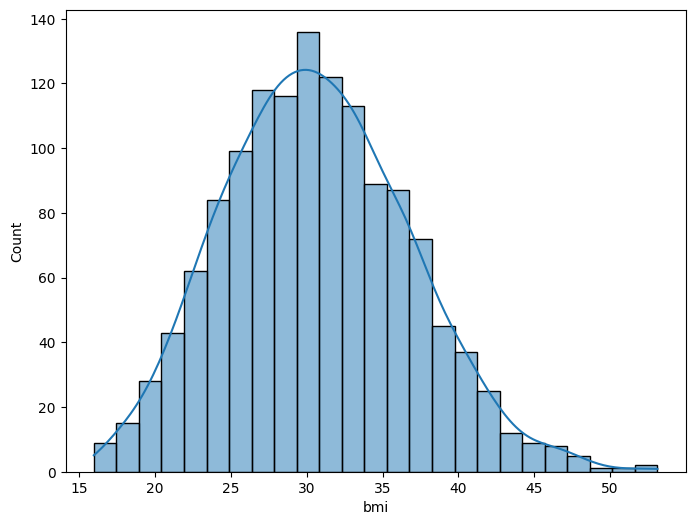

In [391]:
plt.figure(figsize=(8, 6))
sns.histplot(df['bmi'], kde=True) 

In [392]:
df_clean['bmi_category']=pd.cut(df_clean['bmi'],bins=[0, 18.5, 24.9, 29.9, float('inf')], labels=['Underweight', 'Normalweight', 'Overweight', 'Obese'])
#here inf means infinity, which is used to define the upper limit of the last bin. This means that any BMI value greater than 29.9 will be categorized as 'Obese'.

In [393]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normalweight
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


##### now we need to convert the bmi categories too into a numeric value .... because ml models only accept the numeric value

In [394]:
df_clean=pd.get_dummies(df_clean, columns=['bmi_category']) #this creates dummy variables for the 'bmi_category' column in the DataFrame df_clean. The drop_first=True argument is used to avoid the dummy variable trap, which can lead to multicollinearity in regression models. By dropping the first category, we ensure that the remaining categories are independent of each other.

In [395]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normalweight,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,0,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,0,1,0,0,False,False,True,False


In [396]:
df_clean=df_clean.astype(int)

In [397]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normalweight,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0,0,1,0


## Feature Scaling :- Some Models depend on the value(weight) so feature Scaling are needed for such 

#### dependent not on weights 
Linear Regression	Weights/coefficients-
Logistic Regression	Weights/coefficients-
Neural Network	Weights-
SVM	Weights/decision boundary-

##### dependent not on weights:
Decision Tree	Rules/splits-
Random Forest	Many trees-
KNN	Training examples-
Naive Bayes	Probabilities-
K-Means	Centroids-

In [398]:
df_clean.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight',
       'bmi_category_Normalweight', 'bmi_category_Overweight',
       'bmi_category_Obese'],
      dtype='object')

##### age,bmi,charges

In [399]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Program Files\Python39\python.exe -m pip install --upgrade pip' command.


In [400]:
from sklearn.preprocessing import StandardScaler
cols=['age','bmi','children']
scaler=StandardScaler()

df_clean[cols] = scaler.fit_transform(df_clean[cols]) #fit-ley chai sd and mean nikalxa ani transform le chai data lai scale gari replace garxa

In [401]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normalweight,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0


##### hami ley chai output variable lai chalayeko xainau hai cause o/p variable ho

### Feature Extraction

In [402]:
from scipy.stats import pearsonr

# Pearson correlation coefficient is a measure of the linear correlation between two variables. It ranges from -1 to 1, where 1 indicates a perfect positive linear relationship, -1 indicates a perfect negative linear relationship, and 0 indicates no linear relationship.

In [403]:
selected_features = ['age', 'children', 'bmi', 'is_female', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Normalweight', 'bmi_category_Overweight', 'bmi_category_Obese']

correlations = {
    feature: pearsonr(df_clean[feature], df_clean['charges'])[0]
    for feature in selected_features
}

correlations_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'Pearson Correlation']
)

correlations_df.sort_values(
    by='Pearson Correlation',
    ascending=False
)


,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obese,0.200348
2,bmi,0.196236
6,region_southeast,0.073577
1,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_category_Normalweight,-0.104042


#### chi square test == checks the relation beyween categorical varaible , here could be is_female and is_smoker

In [404]:
cat_features = ['is_female', 'is_smoker', 'region_northwest', 'region_southeast',
                 'region_southwest', 'bmi_category_Normalweight', 
                 'bmi_category_Overweight', 'bmi_category_Obese']

#### here during comparision chi square compares category but the charges(target) isnt category value here  so we create a category value for it by using the bins 

In [407]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

# Divide charges into 4 equal-frequency groups
df_clean['charges_bin'] = pd.qcut(
    df_clean['charges'],
    q=4,
    labels=False
)

chi2_results = {}

# Perform chi-square test for each categorical feature
for col in cat_features:
    contingency = pd.crosstab(
        df_clean[col],
        df_clean['charges_bin']
    )

    chi2_statistic, p_value, _, _ = chi2_contingency(contingency)

    decision = (
        "Reject Null {Keep Feature}"
        if p_value < alpha
        else "Accept Null {Drop Feature}"
    )

    chi2_results[col] = {
        'chi2_statistic': chi2_statistic,
        'p_value': p_value,
        'Decision': decision
    }

# Create the final DataFrame outside the loop
chi2_df = pd.DataFrame(chi2_results).T

chi2_df = chi2_df.sort_values(
    by='p_value',
    ascending=True
)

chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null {Keep Feature}
region_southeast,15.998167,0.001135,Reject Null {Keep Feature}
is_female,10.258784,0.01649,Reject Null {Keep Feature}
bmi_category_Obese,8.515711,0.036473,Reject Null {Keep Feature}
region_southwest,5.091893,0.165191,Accept Null {Drop Feature}
bmi_category_Overweight,4.25149,0.235557,Accept Null {Drop Feature}
bmi_category_Normalweight,3.708088,0.29476,Accept Null {Drop Feature}
region_northwest,1.13424,0.768815,Accept Null {Drop Feature}


In [409]:
final_df = df_clean[
    ['age', 'is_female', 'bmi', 'children', 'is_smoker',
     'charges', 'region_southeast', 'bmi_category_Obese']
]

final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1
2,-0.799350,0,0.462463,1.580143,0,4449,1,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0


In [410]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500
